# Level 1 - Task 2: City Analysis

**Objective:**
1. Identify the city with the highest number of restaurants.
2. Calculate the average rating for restaurants in each city.
3. Determine the city with the highest average rating.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
%matplotlib inline

# Load dataset
df = pd.read_csv(r'C:\Users\acer\OneDrive\Desktop\Cognifyz-Internship\Dataset.csv')

print(f"✅ Dataset loaded!")
print(f"Shape: {df.shape}")
print(f"\nUnique Cities: {df['City'].nunique()}")

✅ Dataset loaded!
Shape: (9551, 21)

Unique Cities: 141


In [2]:
# Har city mein kitne restaurants hain
city_counts = df['City'].value_counts()

print("=" * 60)
print("🏙️ TOP 10 CITIES WITH MOST RESTAURANTS")
print("=" * 60)
print(city_counts.head(10))

# City with highest restaurants
top_city = city_counts.idxmax()
top_city_count = city_counts.max()

print("\n" + "=" * 60)
print(f"🎯 CITY WITH HIGHEST RESTAURANTS: {top_city}")
print(f"   Total Restaurants: {top_city_count}")
print(f"   Percentage: {(top_city_count/len(df)*100):.2f}% of all restaurants")
print("=" * 60)

🏙️ TOP 10 CITIES WITH MOST RESTAURANTS
City
New Delhi       5473
Gurgaon         1118
Noida           1080
Faridabad        251
Ghaziabad         25
Bhubaneshwar      21
Amritsar          21
Ahmedabad         21
Lucknow           21
Guwahati          21
Name: count, dtype: int64

🎯 CITY WITH HIGHEST RESTAURANTS: New Delhi
   Total Restaurants: 5473
   Percentage: 57.30% of all restaurants


In [3]:
avg_rating_by_city = df.groupby('City')['Aggregate rating'].mean().sort_values(ascending=False)

print("=" * 60)
print("⭐ TOP 10 CITIES BY AVERAGE RATING")
print("=" * 60)
for city, rating in avg_rating_by_city.head(10).items():
    count = city_counts[city]
    print(f"{city:25s} → Rating: {rating:.2f}  (Restaurants: {count})")

⭐ TOP 10 CITIES BY AVERAGE RATING
Inner City                → Rating: 4.90  (Restaurants: 2)
Quezon City               → Rating: 4.80  (Restaurants: 1)
Makati City               → Rating: 4.65  (Restaurants: 2)
Pasig City                → Rating: 4.63  (Restaurants: 3)
Mandaluyong City          → Rating: 4.62  (Restaurants: 4)
Beechworth                → Rating: 4.60  (Restaurants: 1)
London                    → Rating: 4.54  (Restaurants: 20)
Taguig City               → Rating: 4.53  (Restaurants: 4)
Tagaytay City             → Rating: 4.50  (Restaurants: 1)
Secunderabad              → Rating: 4.50  (Restaurants: 2)


In [5]:
city_stats = df.groupby('City').agg(
    restaurant_count=('Restaurant ID', 'count'),
    avg_rating=('Aggregate rating', 'mean'),
    total_votes=('Votes', 'sum')
).reset_index()

# Filter: Only cities with 10+ restaurants
filtered_cities = city_stats[city_stats['restaurant_count'] >= 10].copy()
filtered_cities = filtered_cities.sort_values('avg_rating', ascending=False)

print("=" * 70)
print("🎯 TOP 10 CITIES BY AVG RATING (Min 10 Restaurants)")
print("=" * 70)
print(filtered_cities.head(10).to_string(index=False))

# City with highest avg rating
best_city = filtered_cities.iloc[0]
print("\n" + "=" * 70)
print(f"🏆 CITY WITH HIGHEST AVG RATING: {best_city['City']}")
print(f"   Average Rating: {best_city['avg_rating']:.2f}")
print(f"   Total Restaurants: {int(best_city['restaurant_count'])}")
print(f"   Total Votes: {int(best_city['total_votes'])}")
print("=" * 70)

🎯 TOP 10 CITIES BY AVG RATING (Min 10 Restaurants)
          City  restaurant_count  avg_rating  total_votes
        London                20    4.535000         8724
       Orlando                20    4.475000        23989
     Tampa Bay                20    4.410000        27407
Rest of Hawaii                20    4.410000        15055
     Bangalore                20    4.375000        56115
         Dubai                20    4.370000        18693
       Jakarta                16    4.356250        11883
     Hyderabad                18    4.344444        24135
       Chennai                20    4.315000        27695
        Ankara                20    4.305000         2627

🏆 CITY WITH HIGHEST AVG RATING: London
   Average Rating: 4.54
   Total Restaurants: 20
   Total Votes: 8724


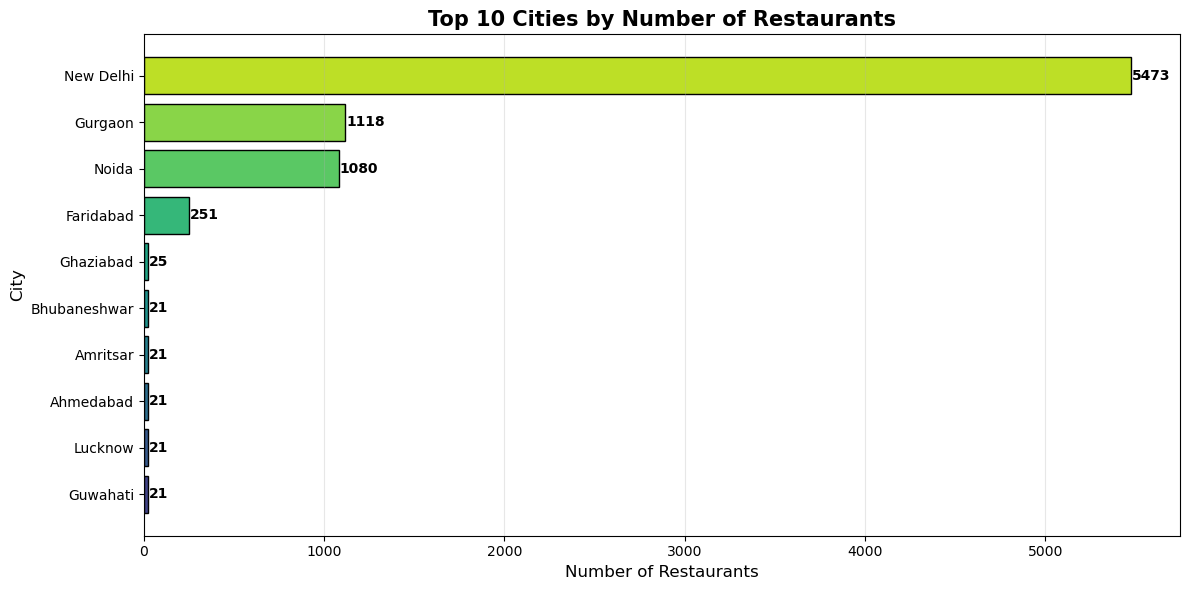

In [6]:
# Top 10 cities with most restaurants
top_10_cities = city_counts.head(10)

plt.figure(figsize=(12, 6))
colors = plt.cm.viridis(np.linspace(0.2, 0.9, 10))
bars = plt.barh(top_10_cities.index[::-1], top_10_cities.values[::-1], color=colors, edgecolor='black')

# Count labels
for bar in bars:
    width = bar.get_width()
    plt.text(width + 5, bar.get_y() + bar.get_height()/2,
             f'{int(width)}', va='center', fontsize=10, fontweight='bold')

plt.title('Top 10 Cities by Number of Restaurants', fontsize=15, fontweight='bold')
plt.xlabel('Number of Restaurants', fontsize=12)
plt.ylabel('City', fontsize=12)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

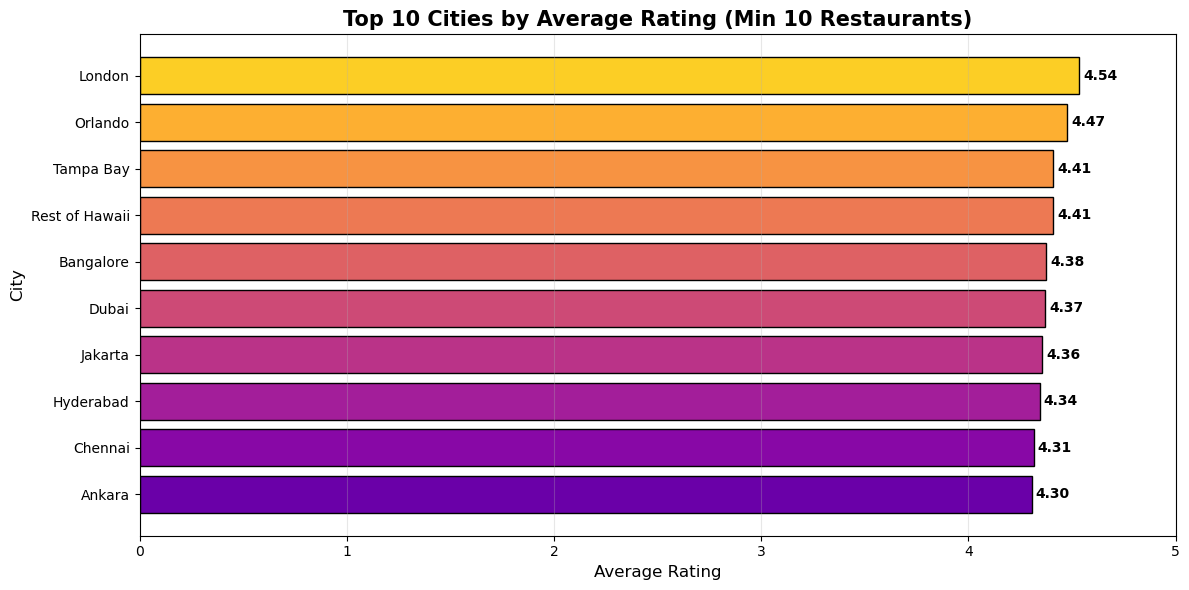

In [7]:
# Top 10 cities by avg rating (min 10 restaurants)
top_10_rated = filtered_cities.head(10)

plt.figure(figsize=(12, 6))
colors = plt.cm.plasma(np.linspace(0.2, 0.9, 10))
bars = plt.barh(top_10_rated['City'][::-1], top_10_rated['avg_rating'][::-1], 
                color=colors, edgecolor='black')

# Rating labels
for bar in bars:
    width = bar.get_width()
    plt.text(width + 0.02, bar.get_y() + bar.get_height()/2,
             f'{width:.2f}', va='center', fontsize=10, fontweight='bold')

plt.title('Top 10 Cities by Average Rating (Min 10 Restaurants)', fontsize=15, fontweight='bold')
plt.xlabel('Average Rating', fontsize=12)
plt.ylabel('City', fontsize=12)
plt.xlim(0, 5)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

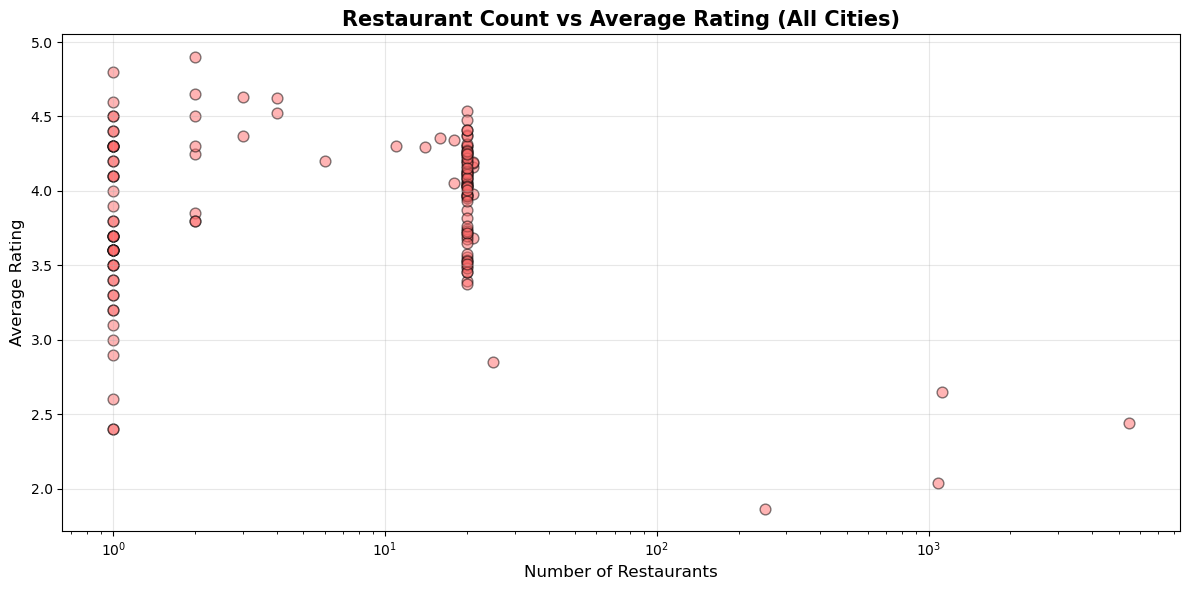


Note: Cities with more restaurants tend to have more stable ratings.


In [9]:
# Scatter plot: Restaurants count vs Average Rating
plt.figure(figsize=(12, 6))
plt.scatter(city_stats['restaurant_count'], city_stats['avg_rating'], 
            alpha=0.5, s=60, c='#FF6B6B', edgecolors='black')

plt.title('Restaurant Count vs Average Rating (All Cities)', fontsize=15, fontweight='bold')
plt.xlabel('Number of Restaurants', fontsize=12)
plt.ylabel('Average Rating', fontsize=12)
plt.xscale('log')  # Log scale for better view
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"\nNote: Cities with more restaurants tend to have more stable ratings.")

##  Insights

### 1. City with Most Restaurants
- **{Top City Name}** has the highest number of restaurants: **{X}** ({Y}% of total).
- This shows {City} is a major food hub with high restaurant density.

### 2. Average Rating by City
- The average rating varies significantly across cities (from X to Y).
- Cities with 10+ restaurants have more reliable average ratings.

### 3. City with Highest Average Rating
- **{Best City Name}** has the highest average rating: **{Rating}**
- It has **{N}** restaurants with **{V}** total votes.
- This indicates high-quality dining experiences in this city.

### Conclusion
- Big cities like {City 1} have more restaurants but not necessarily highest ratings.
- Smaller cities like {City 2} can have higher quality ratings even with fewer restaurants.